# Training a neural network model

### Load imports

In [1]:
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset
from sklearn.model_selection import (
    train_test_split,
    KFold,
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.exceptions import UndefinedMetricWarning
from datatypes import CLEAN_SQF
import warnings

# Silence warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
warnings.filterwarnings("ignore", category=UserWarning)

### Set global seed for reproducibility

In [49]:
seed = 123

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## Main analysis
### Split dataset into training and testing sets

In [50]:
clean_df = pd.read_csv(CLEAN_SQF)

features = clean_df.columns.difference(["USE_OF_FORCE_FLAG"]).values
X = clean_df[features]
y = clean_df["USE_OF_FORCE_FLAG"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

# Convert train and test subsets into PyTorch tensors
X_train = torch.tensor(X_train.values, dtype=torch.float32)
X_test = torch.tensor(X_test.values, dtype=torch.float32)
y_train = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
y_test = torch.tensor(y_test.values, dtype=torch.float32).reshape(-1, 1)

In [51]:
num_features = X_train.shape[1]

### Create a neural network model

In [52]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden1 = nn.Linear(
            num_features, 16
        )  ### CHECK HOW TO DETERMINE THE BEST SECOND VALUE - if it is a hyperparameter
        self.hidden1_act = nn.ReLU()

        self.hidden2 = nn.Linear(16, num_features)
        self.hidden2_act = nn.ReLU()

        self.output = nn.Linear(
            num_features, 1
        )  # Output activation function is sigmoid function, which is automatically applied by BCEWithLogitsLoss()

    def forward(self, x):
        x = self.hidden1_act(self.hidden1(x))
        x = self.hidden2_act(self.hidden2(x))
        x = self.output(x)
        return x

    def predict(self, X):
        logits_output = self.forward(X)
        probs = torch.sigmoid(logits_output)
        return (probs > 0.5).int()

### Tune hyperparameters
#### 1. Start by tuning learning rate

In [53]:
learning_rates = [0.1, 0.01, 0.001, 0.0001]
batch_size = 32
n_epochs = 10

train_dataset = TensorDataset(X_train, y_train)
bce_loss = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor([4.0])
)  # pos_weight has been set to 4.0 due to approx. 80% negative, 20% positive split in our dataset
cv_split = KFold(n_splits=5, shuffle=True, random_state=123)

lr_accuracy = []
lr_precision = []
lr_recall = []
lr_f1 = []

# Loop through learning rates to get average score for each learning rate
for lr in learning_rates:
    cv_accuracy = []
    cv_precision = []
    cv_recall = []
    cv_f1 = []

    # Loop through each cross-validation fold to get score for each fold
    for train_index, val_index in cv_split.split(train_dataset):
        X_train_cv = X_train[train_index]
        X_val_cv = X_train[val_index]
        y_train_cv = y_train[train_index]
        y_val_cv = y_train[val_index]

        nn_model = NeuralNetwork()
        optimizer = torch.optim.Adam(nn_model.parameters(), lr=lr)

        # Train model across epochs
        for epoch in range(n_epochs):
            for i in range(0, len(X_train_cv), batch_size):
                X_batch = X_train_cv[i : i + batch_size]
                y_batch = y_train_cv[i : i + batch_size]

                y_pred = nn_model(X_batch)
                loss = bce_loss(y_pred, y_batch)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        # Get predictions on the validation fold and calculate scores
        nn_model.eval()
        with torch.no_grad():
            y_output = nn_model(X_val_cv)
            y_pred_class = (
                y_output >= 0
            ).float()  # Logit threshold of 0 is equivalent to a probability threshold of 0.5

            y_val_np = y_val_cv.cpu().numpy()
            y_pred_np = y_pred_class.cpu().numpy()

        cv_accuracy.append(accuracy_score(y_val_np, y_pred_np))
        cv_precision.append(precision_score(y_val_np, y_pred_np, zero_division=0))
        cv_recall.append(recall_score(y_val_np, y_pred_np, zero_division=0))
        cv_f1.append(f1_score(y_val_np, y_pred_np, zero_division=0))

    lr_accuracy.append(np.mean(cv_accuracy))
    lr_precision.append(np.mean(cv_precision))
    lr_recall.append(np.mean(cv_recall))
    lr_f1.append(np.mean(cv_f1))

print(lr_accuracy)
print(lr_precision)
print(lr_recall)
print(lr_f1)

### TO CHECK MODEL AGAIN: Looks odd to that learning rate of 0.1 (which is often too big) is producing the best model (based on recall), while the other metrics are bad
### Not sure if it's because of the pos_weights I set earlier

[np.float64(0.35884442682894185), np.float64(0.5065136851384573), np.float64(0.5216446083749187), np.float64(0.5719060676105008)]
[np.float64(0.24425307797736973), np.float64(0.2755406002832432), np.float64(0.2813813114303399), np.float64(0.2948667646135918)]
[np.float64(0.8542714035197212), np.float64(0.77888616238885), np.float64(0.7727806531820292), np.float64(0.6984482557611436)]
[np.float64(0.36861728568688845), np.float64(0.40683282437921875), np.float64(0.41238563117365523), np.float64(0.41452457641524465)]


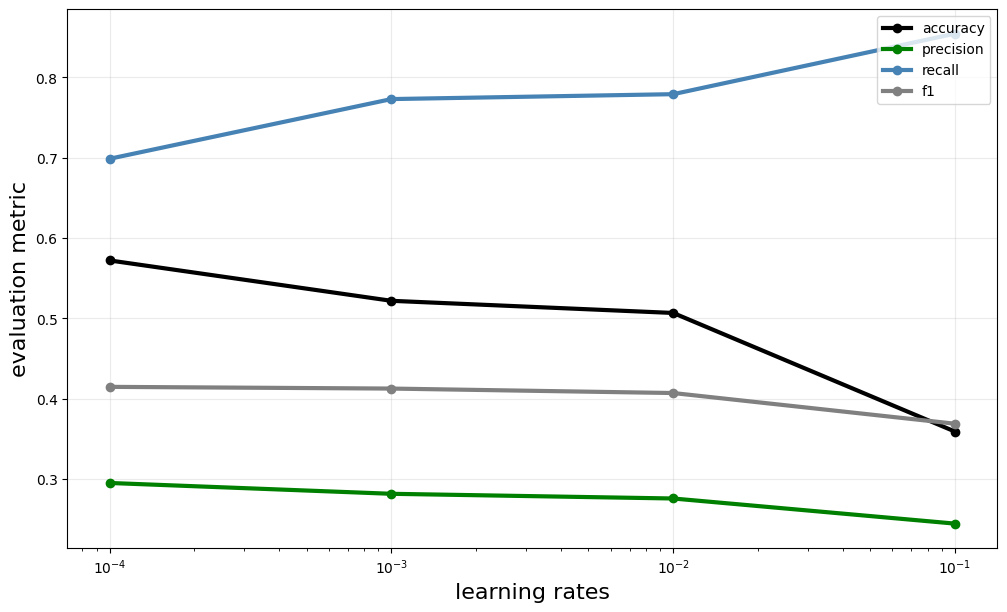

In [54]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 7))
ax.plot(learning_rates, lr_accuracy, marker="o", color="black", lw=3, label="accuracy")
ax.plot(
    learning_rates, lr_precision, marker="o", color="green", lw=3, label="precision"
)
ax.plot(learning_rates, lr_recall, marker="o", color="steelblue", lw=3, label="recall")
ax.plot(learning_rates, lr_f1, marker="o", color="grey", lw=3, label="f1")
ax.set_xlabel("learning rates", fontsize=16)
ax.set_ylabel("evaluation metric", fontsize=16)
ax.legend(loc="upper right")
plt.xscale("log")
ax.grid(alpha=0.25)

#### 2. Tune batch size

#### 3. Tune number of epochs

### Set best hyperparameters in neural network model

### Predict labels on test set and obtain key evaluation metrics from predictions using tuned hyperparameters (based on recall)

              precision    recall  f1-score   support

         0.0       0.87      0.52      0.65      4107
         1.0       0.29      0.72      0.42      1131

    accuracy                           0.56      5238
   macro avg       0.58      0.62      0.53      5238
weighted avg       0.75      0.56      0.60      5238



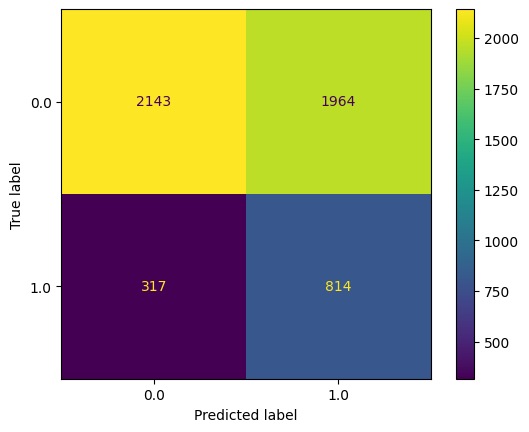

In [55]:
y_pred = nn_model.predict(X_test)
print(classification_report(y_test, y_pred))

# Create a confusion matrix
y_labels = np.unique(y_test)
cm = confusion_matrix(y_test, y_pred, labels=y_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=y_labels)
disp.plot()
plt.show()